<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Entregable_6_Transformaciones_Sintetico_Crescente_Mauricio_35564222.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entregable 6 – Transformación Avanzada de Variables
### Dataset sintético · Resumen de transformaciones · Análisis de histogramas · Impacto en modelos

**Estructura del notebook**
1. Generación del dataset sintético
2. Resumen de las transformaciones (tabla guía)
3. Análisis de histogramas: asimetría y efecto de cada transformación
4. Escalado: Min-Max y Estandarización
5. Codificación de variables categóricas
6. Prevención de *data leakage* con `Pipeline` y `ColumnTransformer`
7. **Impacto en modelos**: KNN, Regresión Logística y PCA, medidos con validación cruzada
8. Tabla resumen y conclusiones

In [ ]:
# --- Librerías ---
import warnings
import pandas as pd                                         # tablas
import numpy as np                                          # cálculo numérico y azar
import matplotlib.pyplot as plt                             # gráficos
import seaborn as sns                                       # gráficos estadísticos

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold  # separar datos y validar
from sklearn.preprocessing import (MinMaxScaler, StandardScaler,                        # escaladores
                                   OneHotEncoder, OrdinalEncoder,                       # codificadores
                                   PowerTransformer, FunctionTransformer)               # transformaciones de potencia / funciones
from sklearn.compose import ColumnTransformer               # transformaciones distintas por columna
from sklearn.pipeline import Pipeline                       # encadena transformaciones + modelo
from sklearn.neighbors import KNeighborsClassifier          # modelo basado en distancia
from sklearn.linear_model import LogisticRegression         # modelo basado en gradiente
from sklearn.decomposition import PCA                       # reducción de dimensionalidad
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)   # silencia avisos de convergencia (los contamos aparte)
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 160)

## 1. Generación del dataset sintético

Simulamos 2000 clientes de un comercio con el objetivo de predecir si **compran** (`compra` = 1) o no. El dataset está diseñado para que cada transformación tenga una razón de ser:

| Variable | Tipo | Característica diseñada |
|---|---|---|
| `edad` | numérica | Normal (simétrica), escala ~18–80 |
| `ingreso` | numérica | **Muy asimétrica** (lognormal), escala de decenas de miles |
| `gasto_mensual` | numérica | **Asimétrica** (exponencial), escala de cientos |
| `antiguedad_meses` | numérica | Uniforme, escala 0–120 |
| `score_credito` | numérica | Uniforme, escala 300–850 |
| `visitas_web` | numérica | Conteos pequeños (Poisson), escala ~0–15 |
| `saldo_cuenta` | numérica | **Escala enorme (hasta 2.000.000) y sin relación con la compra** (ruido). Se agrega a propósito para mostrar qué pasa cuando una variable irrelevante tiene una escala gigante |
| `ciudad` | categórica **nominal** | 4 ciudades sin orden, con efecto distinto en la compra |
| `nivel_educativo` | categórica **ordinal** | primario < secundario < terciario < universitario |
| `codigo_postal` | categórica de **alta cardinalidad** | ~300 códigos sin efecto real (solo ruido) |
| `compra` | objetivo binario | Depende de `log(ingreso)`, `score`, `edad`, educación y ciudad |

In [ ]:
rng = np.random.default_rng(42)        # generador aleatorio con semilla fija -> resultados reproducibles
n = 2000                               # cantidad de clientes

# ---------- Variables numéricas ----------
edad = np.clip(rng.normal(40, 12, n), 18, 80)                       # normal: media 40, desvío 12, acotada 18–80
# Ingreso: exp(normal) = lognormal -> asimetría fuerte a la derecha; crece levemente con la edad
ingreso = np.exp(10.3 + 0.01 * (edad - 40) + rng.normal(0, 0.6, n))
# Gasto: exponencial con media que crece un poco con el ingreso (muchos gastos chicos, pocos enormes)
gasto_mensual = rng.exponential(scale=200 + ingreso * 0.004)
antiguedad_meses = rng.integers(0, 121, n)                          # entero 0–120 (uniforme)
score_credito = rng.uniform(300, 850, n)                            # uniforme 300–850
visitas_web = rng.poisson(5, n)                                     # conteos con media 5

# ---------- Variables categóricas ----------
ciudades = np.array(['Cordoba', 'Mendoza', 'Rosario', 'Salta'])
ciudad = rng.choice(ciudades, n)                                    # nominal (sin orden natural)

niveles = np.array(['primario', 'secundario', 'terciario', 'universitario'])
nivel_educativo = rng.choice(niveles, n, p=[.15, .35, .3, .2])      # ordinal (con orden natural)

codigo_postal = rng.choice([f'CP{i:03d}' for i in range(300)], n)   # 300 categorías: alta cardinalidad (sin efecto real)

# ---------- Variable objetivo: probabilidad de compra ----------
z = lambda v: (v - v.mean()) / v.std()                              # estandariza (solo para construir el objetivo)
efecto_ciudad = pd.Series(ciudad).map({'Cordoba': 0.8, 'Mendoza': -0.8,       # efecto NO monótono respecto al orden
                                       'Rosario': 0.4, 'Salta': -0.4}).values  # alfabético (a propósito, ver sección 5)
educ_num = pd.Series(nivel_educativo).map({'primario': 0, 'secundario': 1, 'terciario': 2, 'universitario': 3}).values

logit = (-0.2 + 1.2 * z(np.log(ingreso)) + 0.6 * z(score_credito)    # el ingreso influye vía su LOGARITMO
         - 0.4 * z(edad) + 0.4 * z(educ_num) + efecto_ciudad)
prob = 1 / (1 + np.exp(-logit))                                      # función sigmoide -> probabilidad
compra = rng.binomial(1, prob)                                       # 0/1 sorteado según esa probabilidad

# Variable de ruido con escala enorme: se genera DESPUÉS del objetivo, por lo que no influye en 'compra'
saldo_cuenta = rng.uniform(0, 2_000_000, n).round(0)

df = pd.DataFrame({'edad': edad.round(1), 'ingreso': ingreso.round(0), 'gasto_mensual': gasto_mensual.round(2),
                   'antiguedad_meses': antiguedad_meses, 'score_credito': score_credito.round(0),
                   'visitas_web': visitas_web, 'saldo_cuenta': saldo_cuenta, 'ciudad': ciudad, 'nivel_educativo': nivel_educativo,
                   'codigo_postal': codigo_postal, 'compra': compra})

print("Forma:", df.shape, "| Proporción de compra =", round(df['compra'].mean(), 3))
df.head()

Forma: (2000, 11) | Proporción de compra = 0.47


,edad,ingreso,gasto_mensual,antiguedad_meses,score_credito,visitas_web,saldo_cuenta,ciudad,nivel_educativo,codigo_postal,compra
0,43.7,23515.0,107.70,80,577.0,2,595127.0,Mendoza,primario,CP236,1
1,27.5,17600.0,266.63,118,600.0,6,1283663.0,Rosario,universitario,CP296,0
2,49.0,42212.0,207.10,47,704.0,7,419257.0,Mendoza,terciario,CP195,0
3,51.3,38715.0,117.92,51,657.0,6,1393701.0,Salta,universitario,CP073,0
4,18.0,10271.0,94.58,68,497.0,3,860342.0,Rosario,terciario,CP102,0


In [ ]:
# Estadísticos descriptivos: fíjate en las escalas tan distintas entre variables (saldo_cuenta en 10^6, ingreso en 10^4–10^5, visitas en 10^0)
num_cols = ['edad', 'ingreso', 'gasto_mensual', 'antiguedad_meses', 'score_credito', 'visitas_web', 'saldo_cuenta']
df[num_cols].describe().round(1)

,edad,ingreso,gasto_mensual,antiguedad_meses,score_credito,visitas_web,saldo_cuenta
count,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0,2000.0
mean,39.5,36028.4,330.3,59.5,577.4,5.1,1001828.6
std,11.6,24181.4,363.0,34.9,158.4,2.2,572360.1
min,18.0,4939.0,0.2,0.0,301.0,0.0,270.0
25%,31.4,19509.0,87.6,30.0,443.0,3.0,506728.2
50%,39.7,30026.5,216.0,59.0,579.0,5.0,997345.5
75%,47.2,44974.5,449.4,90.0,711.0,6.0,1484190.0
max,78.1,188301.0,3026.1,120.0,850.0,15.0,1999914.0


In [ ]:
# Cardinalidad de las variables categóricas (cantidad de categorías distintas)
print(df[['ciudad', 'nivel_educativo', 'codigo_postal']].nunique())

ciudad               4
nivel_educativo      4
codigo_postal      299
dtype: int64


## 2. Resumen de las transformaciones

| Transformación | Qué hace | Cuándo usarla | Modelos que la necesitan |
|---|---|---|---|
| **Min-Max Scaling** | `(x − min)/(max − min)` → rango [0, 1] | Distribución no gaussiana; se necesita rango acotado | KNN, SVM, redes neuronales |
| **StandardScaler (Z-score)** | `(x − μ)/σ` → media 0, desvío 1 | Variables con escalas distintas; conserva la información de outliers | Regresión logística/lineal, SVM, PCA, redes neuronales |
| **Logaritmo / raíz cuadrada** | Comprime la cola derecha | Asimetría positiva (ingresos, precios, conteos) | Modelos lineales y basados en distancia |
| **Box-Cox** | Busca el exponente λ que maximiza la normalidad | Asimetría con valores **estrictamente positivos** | Modelos que asumen normalidad |
| **Yeo-Johnson** | Igual que Box-Cox pero admite ceros y negativos | Asimetría con cualquier signo | Ídem |
| **Label / Ordinal Encoding** | Categorías → enteros | **Solo** variables ordinales (con orden explícito) | Cualquiera |
| **One-Hot Encoding** | Una columna 0/1 por categoría (`drop='first'` en lineales) | Variables nominales de baja cardinalidad | Cualquiera (lineales: usar `drop`) |

> **Regla de oro:** todo `fit` (escaladores, encoders, power transforms) se hace **solo con train**; sobre test solo se aplica `transform`.

## 3. Análisis de histogramas

### 3.1 Distribuciones originales y asimetría

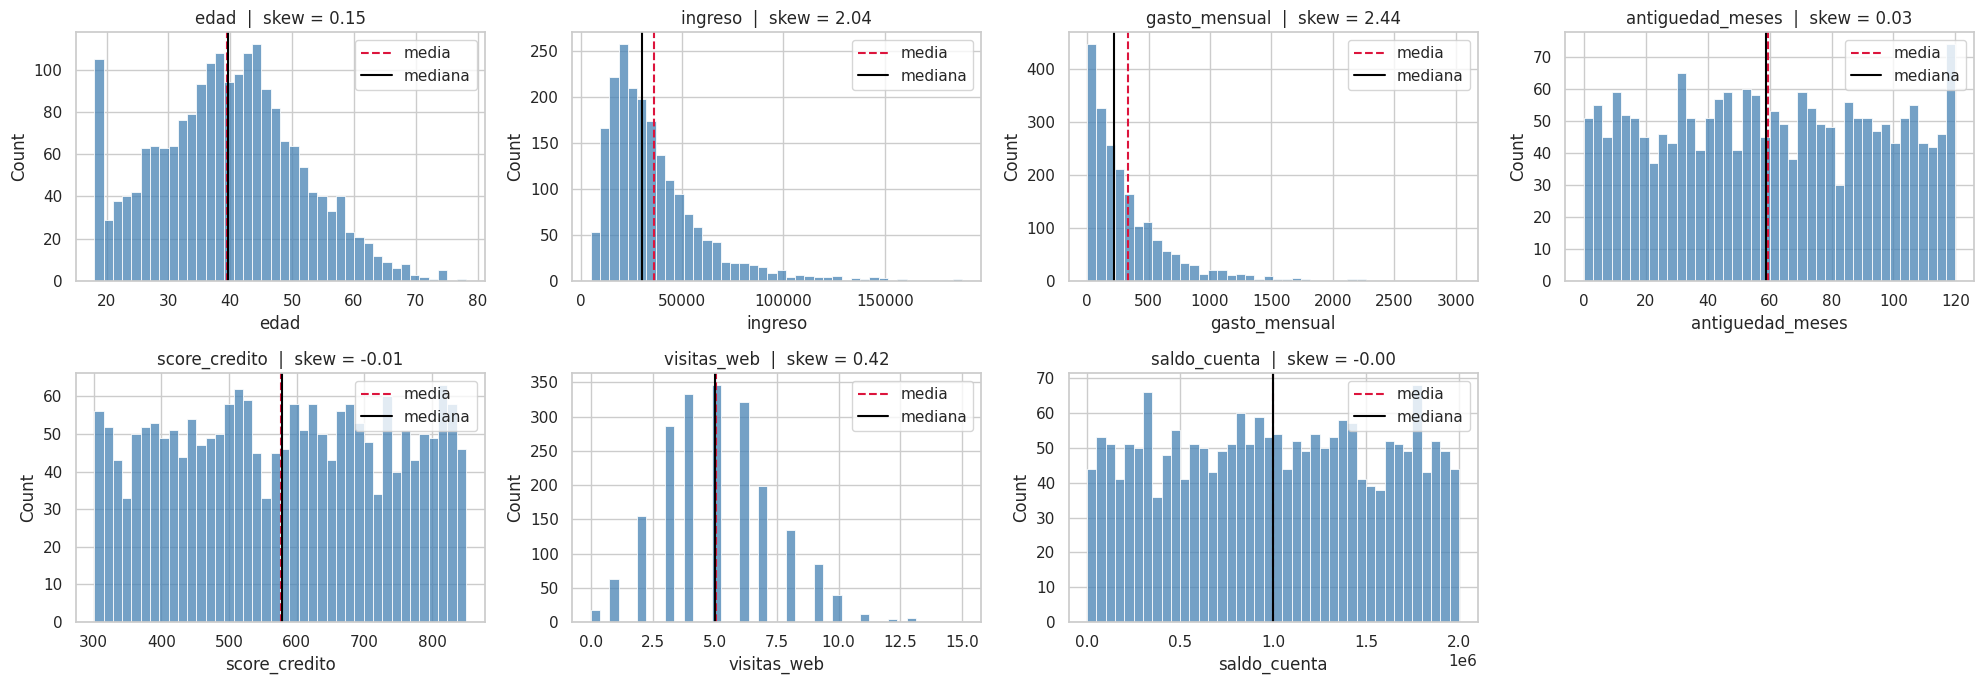

Asimetría de cada variable:
gasto_mensual       2.44
ingreso             2.04
visitas_web         0.42
edad                0.15
antiguedad_meses    0.03
saldo_cuenta       -0.00
score_credito      -0.01
dtype: float64


In [ ]:
# Histogramas de las 7 variables numéricas, con la media (línea punteada) y la mediana (línea sólida)
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
axes.ravel()[-1].axis('off')                 # el 8.º casillero queda vacío (solo hay 7 variables)
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=40, ax=ax, color='steelblue')
    ax.axvline(df[col].mean(), color='crimson', ls='--', label='media')      # media: se desplaza hacia la cola
    ax.axvline(df[col].median(), color='black', label='mediana')             # mediana: resistente a la cola
    ax.set_title(f"{col}  |  skew = {df[col].skew():.2f}"); ax.legend()
plt.tight_layout(); plt.show()

# Asimetría (skewness): ~0 simétrica, >0 cola derecha, <0 cola izquierda; |skew| < 0.5 ~ simétrica
print("Asimetría de cada variable:")
print(df[num_cols].skew().round(2).sort_values(ascending=False))

**Lectura:**
- `ingreso` (skew 2,04) y `gasto_mensual` (skew 2,44) tienen una **cola derecha larga**: la media (≈ 36.000 y ≈ 330) queda bien a la derecha de la mediana (≈ 30.000 y ≈ 216). Son las candidatas a una transformación de potencia.
- `visitas_web` (0,42) tiene un sesgo leve; `edad`, `antiguedad_meses`, `score_credito` y `saldo_cuenta` son simétricas (skew ≈ 0) y **no necesitan** transformación.
- Aunque `saldo_cuenta` es simétrica, su escala (hasta 2.000.000) es enorme: es un problema de **escala**, no de forma.

### 3.2 Efecto de cada transformación sobre las variables asimétricas

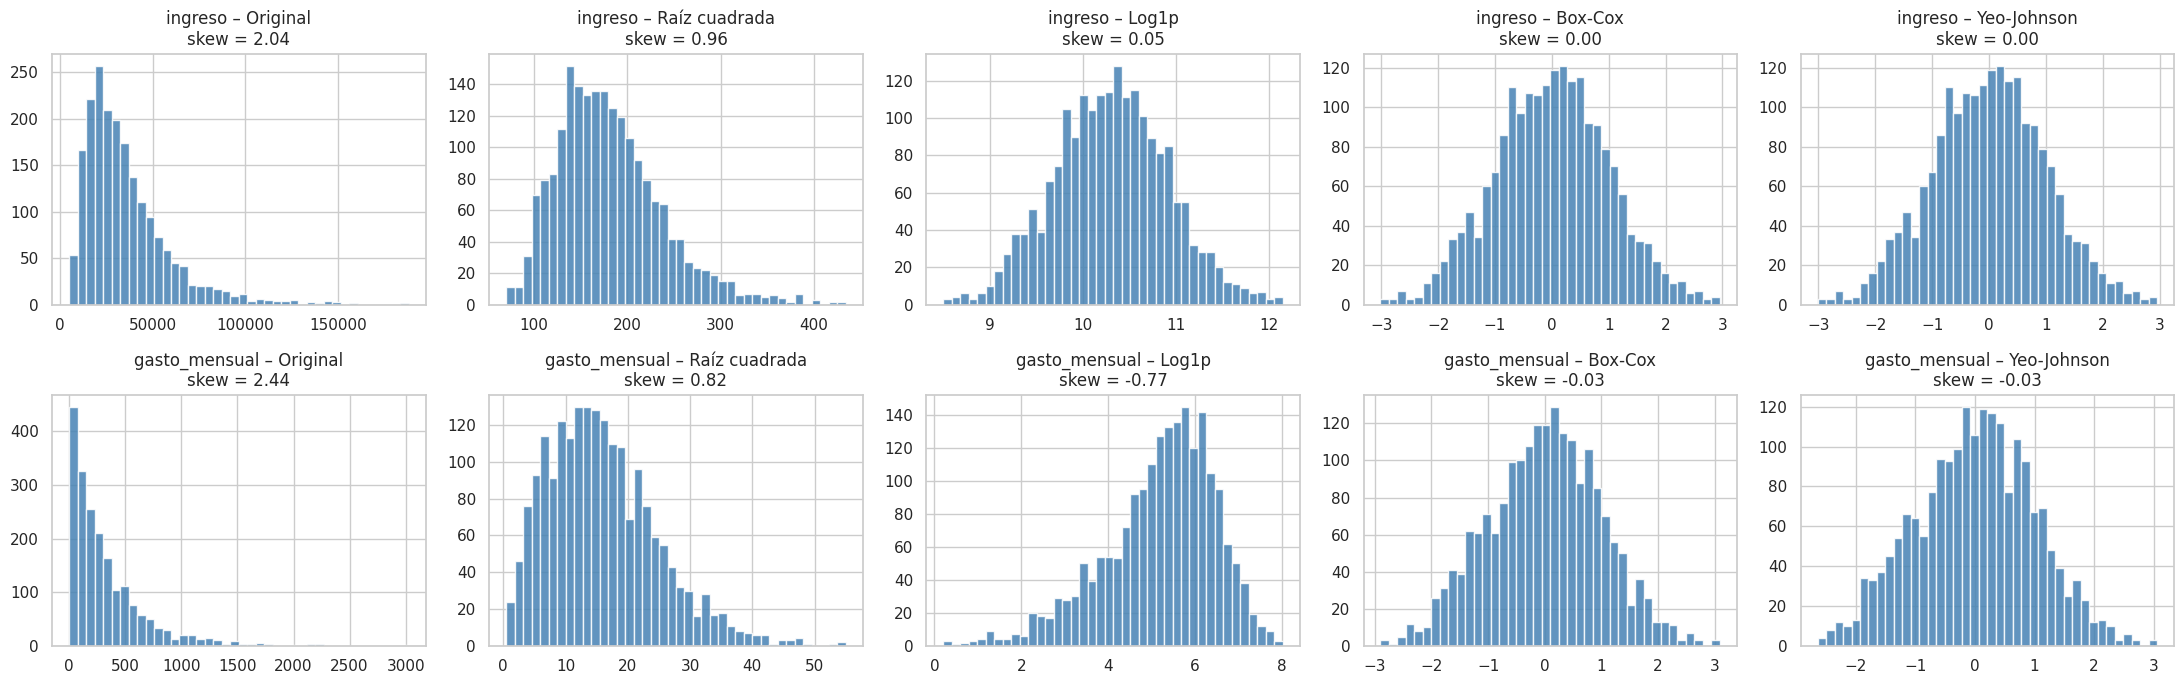

,Original,Raíz cuadrada,Log1p,Box-Cox,Yeo-Johnson
ingreso,2.04,0.96,0.05,0.00,0.00
gasto_mensual,2.44,0.82,-0.77,-0.03,-0.03


In [ ]:
skewed = ['ingreso', 'gasto_mensual']      # variables con asimetría marcada
tabla_skew = {}                              # aquí guardaremos la asimetría resultante de cada transformación

fig, axes = plt.subplots(2, 5, figsize=(22, 7))
for fila, col in enumerate(skewed):
    x = df[[col]]                            # doble corchete: los transformadores de sklearn esperan una matriz 2D
    versiones = {
        'Original': x[col].values,
        'Raíz cuadrada': np.sqrt(x[col].values),                                              # compresión suave
        'Log1p': np.log1p(x[col].values),                                                     # compresión fuerte
        'Box-Cox': PowerTransformer(method='box-cox').fit_transform(x).ravel(),               # requiere valores > 0
        'Yeo-Johnson': PowerTransformer(method='yeo-johnson').fit_transform(x).ravel(),       # admite cualquier valor
    }
    tabla_skew[col] = {}
    for ax, (nombre, v) in zip(axes[fila], versiones.items()):
        sk = pd.Series(v).skew()
        tabla_skew[col][nombre] = round(sk, 2)
        ax.hist(v, bins=40, color='steelblue', alpha=.85, edgecolor='white')
        ax.set_title(f"{col} – {nombre}\nskew = {sk:.2f}")
plt.tight_layout(); plt.show()

pd.DataFrame(tabla_skew).T      # filas = variables, columnas = transformaciones

**Lectura:**
- **`ingreso`:** la raíz cuadrada reduce el skew de 2,04 a 0,96 (mejora, pero insuficiente); `log1p`, Box-Cox y Yeo-Johnson lo dejan prácticamente en 0.
- **`gasto_mensual`:** la raíz cuadrada baja el skew a 0,82, pero **`log1p` lo sobrecorrige** (−0,77, ahora con cola izquierda). Box-Cox y Yeo-Johnson, que buscan el exponente óptimo, lo dejan en −0,03.
- **Moraleja:** el logaritmo no es universal; funciona bien con la lognormal (`ingreso`) y comprime de más a la exponencial (`gasto_mensual`). Las transformaciones de potencia ajustan el exponente solas.
- Box-Cox y Yeo-Johnson dan casi lo mismo porque todos los valores son positivos; Yeo-Johnson solo aporta ventaja cuando hay ceros o negativos.

### 3.3 El escalado cambia la escala, **no la forma**
Min-Max y StandardScaler son transformaciones lineales: mueven y estiran el eje, pero la asimetría queda intacta.

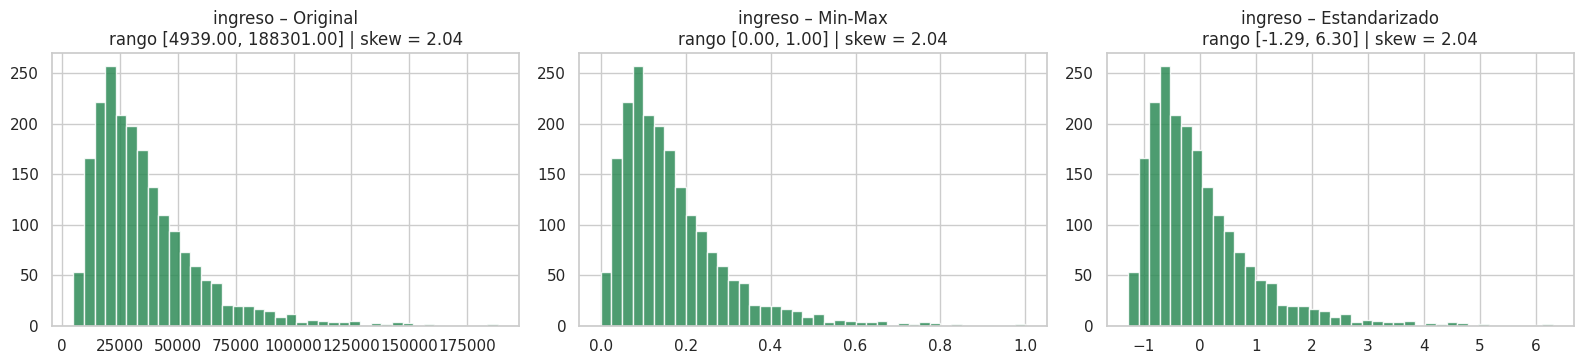

In [ ]:
x = df[['ingreso']]
versiones = {'Original': x['ingreso'].values,
             'Min-Max': MinMaxScaler().fit_transform(x).ravel(),            # rango [0, 1]
             'Estandarizado': StandardScaler().fit_transform(x).ravel()}    # media 0, desvío 1

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (nombre, v) in zip(axes, versiones.items()):
    ax.hist(v, bins=40, color='seagreen', alpha=.85, edgecolor='white')
    ax.set_title(f"ingreso – {nombre}\nrango [{v.min():.2f}, {v.max():.2f}] | skew = {pd.Series(v).skew():.2f}")
plt.tight_layout(); plt.show()

**Lectura:** el skew sigue siendo 2,04 en las tres versiones. Min-Max cambia el rango a [0, 1] y la estandarización centra en 0 con desvío 1, pero **la forma del histograma es idéntica**. Escalar no corrige asimetría: para eso hacen falta las transformaciones no lineales de la sección 3.2.

## 4. Escalado y prevención de *data leakage*

**Primero se separa train/test, después se ajusta el escalador solo con train.** Si se escalara todo y luego se separara, el mínimo, máximo, media y desvío del conjunto de prueba influirían en la transformación del entrenamiento.

In [ ]:
# Separamos X (características) e y (objetivo)
X = df.drop(columns=['compra'])
y = df['compra']

# Split ANTES de transformar. stratify=y mantiene la misma proporción de compra en train y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Ajustamos Min-Max SOLO con train y lo aplicamos a ambos conjuntos
mm = MinMaxScaler().fit(X_train[num_cols])                    # fit: aprende min y max de TRAIN
tr = pd.DataFrame(mm.transform(X_train[num_cols]), columns=num_cols)   # transform sobre train
te = pd.DataFrame(mm.transform(X_test[num_cols]),  columns=num_cols)   # transform sobre test (con min/max de TRAIN)

print("\nTRAIN – rango tras Min-Max (siempre exactamente [0, 1]):")
print(tr.agg(['min', 'max']).round(3))
print("\nTEST – rango tras Min-Max (puede salirse levemente de [0, 1]: es lo correcto, no hubo leakage):")
print(te.agg(['min', 'max']).round(3))

Train: (1500, 10) | Test: (500, 10)

TRAIN – rango tras Min-Max (siempre exactamente [0, 1]):
     edad  ingreso  gasto_mensual  antiguedad_meses  score_credito  visitas_web  saldo_cuenta
min   0.0      0.0            0.0               0.0            0.0          0.0           0.0
max   1.0      1.0            1.0               1.0            1.0          1.0           1.0

TEST – rango tras Min-Max (puede salirse levemente de [0, 1]: es lo correcto, no hubo leakage):
      edad  ingreso  gasto_mensual  antiguedad_meses  score_credito  visitas_web  saldo_cuenta
min  0.000   -0.000          0.000               0.0            0.0        0.000        -0.000
max  0.948    0.775          0.747               1.0            1.0        0.867         0.999


## 5. Codificación de variables categóricas

In [ ]:
# --- 5.1 Nominal: Label (ordinal) Encoding vs One-Hot sobre 'ciudad' ---
# OrdinalEncoder sin orden explícito asigna números por orden alfabético
oe = OrdinalEncoder().fit(X_train[['ciudad']])
print("Ordinal sobre variable NOMINAL (orden alfabético):",
      {c: int(i) for i, c in enumerate(oe.categories_[0])},
      "-> el modelo 'cree' que Salta (3) es el triple de Mendoza (1): orden inexistente")

# One-Hot: 3 columnas (drop='first' quita Cordoba, que queda implícita cuando las otras 3 valen 0)
ohe = OneHotEncoder(drop='first', sparse_output=False).fit(X_train[['ciudad']])
print("\nOne-Hot (drop='first') columnas:", list(ohe.get_feature_names_out()))

# --- 5.2 Ordinal: orden EXPLÍCITO para nivel_educativo ---
oe_edu = OrdinalEncoder(categories=[['primario', 'secundario', 'terciario', 'universitario']]).fit(X_train[['nivel_educativo']])
print("\nOrdinal con orden explícito:", {c: int(i) for i, c in enumerate(oe_edu.categories_[0])})

# --- 5.3 Alta cardinalidad: One-Hot sobre 'codigo_postal' ---
ohe_cp = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X_train[['codigo_postal']])
print(f"\nOne-Hot sobre codigo_postal genera {len(ohe_cp.get_feature_names_out())} columnas nuevas "
      f"para solo {len(X_train)} filas de entrenamiento (maldición de la dimensionalidad)")

Ordinal sobre variable NOMINAL (orden alfabético): {'Cordoba': 0, 'Mendoza': 1, 'Rosario': 2, 'Salta': 3} -> el modelo 'cree' que Salta (3) es el triple de Mendoza (1): orden inexistente

One-Hot (drop='first') columnas: ['ciudad_Mendoza', 'ciudad_Rosario', 'ciudad_Salta']

Ordinal con orden explícito: {'primario': 0, 'secundario': 1, 'terciario': 2, 'universitario': 3}

One-Hot sobre codigo_postal genera 298 columnas nuevas para solo 1500 filas de entrenamiento (maldición de la dimensionalidad)


## 6. `Pipeline` + `ColumnTransformer`

El `Pipeline` garantiza que en cada `fit` las transformaciones se ajusten únicamente con los datos de entrenamiento (incluso dentro de cada *fold* de la validación cruzada). Es la forma segura de integrar transformación y modelo.

In [ ]:
# Aplicamos la transformación logarítmica a las asimétricas ANTES del split lógico (es sin estado: no aprende nada de los datos,
# por lo tanto no hay riesgo de leakage). Creamos columnas nuevas para poder comparar con las originales.
df['ingreso_log'] = np.log1p(df['ingreso'])
df['gasto_log'] = np.log1p(df['gasto_mensual'])

y = df['compra']
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # 5 folds estratificados, siempre el mismo sorteo

def evaluar(pipe, X, scoring='accuracy'):
    # Devuelve la media de la métrica en validación cruzada (5 folds).
    # Dentro de cada fold el Pipeline hace fit del preprocesamiento solo con las filas de entrenamiento de ese fold.
    return cross_val_score(pipe, X, y, cv=cv, scoring=scoring).mean()

resultados = []   # lista donde acumularemos todos los experimentos: [experimento, variante, métrica, valor]
print("Funciones listas.")

Funciones listas.


## 7. Impacto en modelos

### 7.1 Escalado en KNN (modelo basado en distancia)
KNN clasifica según la distancia euclidiana. Sin escalar, las variables de mayor escala pesan más en la distancia, sean o no informativas. Lo medimos de dos formas: (a) qué porcentaje de la distancia aporta cada variable y (b) qué pasa con la accuracy cuando solo cambiamos la **unidad** de `saldo_cuenta` (pesos, miles de pesos, centavos), algo que un buen modelo no debería notar.

In [ ]:
X_num = df[num_cols]                                         # solo variables numéricas (KNN no admite texto)

variantes_knn = {
    'Sin escalar':   Pipeline([('knn', KNeighborsClassifier(n_neighbors=15))]),
    'Min-Max':       Pipeline([('sc', MinMaxScaler()),   ('knn', KNeighborsClassifier(n_neighbors=15))]),
    'Estandarizado': Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=15))]),
}
for nombre, pipe in variantes_knn.items():
    acc = evaluar(pipe, X_num)
    resultados.append(['Escalado en KNN', nombre, 'accuracy (CV)', round(acc, 3)])
    print(f"KNN – {nombre:14s}: accuracy CV = {acc:.3f}")

KNN – Sin escalar   : accuracy CV = 0.647
KNN – Min-Max       : accuracy CV = 0.622


KNN – Estandarizado : accuracy CV = 0.641


In [ ]:
# (a) Peso de cada variable en la distancia euclidiana: promedio de (diferencia)^2 entre 5000 pares aleatorios de clientes
rng2 = np.random.default_rng(0)
pares = rng2.integers(0, len(df), size=(5000, 2))        # índices de 5000 pares de clientes

def peso_en_distancia(X):
    d2 = (X[pares[:, 0]] - X[pares[:, 1]]) ** 2          # diferencia al cuadrado, variable por variable
    medias = d2.mean(axis=0)
    return medias / medias.sum() * 100                   # porcentaje del total

X_raw = df[num_cols].values
X_std = StandardScaler().fit_transform(df[num_cols])
print("Porcentaje de la distancia al cuadrado que aporta cada variable:")
print(pd.DataFrame({'sin escalar (%)': peso_en_distancia(X_raw),
                    'estandarizado (%)': peso_en_distancia(X_std)}, index=num_cols).round(1))

Porcentaje de la distancia al cuadrado que aporta cada variable:
                  sin escalar (%)  estandarizado (%)
edad                          0.0               14.1
ingreso                       0.2               14.4
gasto_mensual                 0.0               14.2
antiguedad_meses              0.0               14.3
score_credito                 0.0               14.7
visitas_web                   0.0               14.1
saldo_cuenta                 99.8               14.2


In [ ]:
# (b) Sensibilidad a la unidad de medida: multiplicamos saldo_cuenta por un factor (equivale a cambiar la unidad)
filas = []
for factor, etiqueta in [(0.001, 'saldo en miles de $'), (1, 'saldo en $ (original)'), (100, 'saldo en centavos')]:
    Xs = df[num_cols].copy()
    Xs['saldo_cuenta'] = Xs['saldo_cuenta'] * factor
    a_raw = evaluar(Pipeline([('knn', KNeighborsClassifier(n_neighbors=15))]), Xs)                              # sin escalar
    a_std = evaluar(Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=15))]), Xs)  # estandarizado
    filas.append([etiqueta, round(a_raw, 3), round(a_std, 3)])
    resultados.append(['Unidad de saldo_cuenta en KNN', etiqueta, 'accuracy CV sin escalar / estandarizado', f"{a_raw:.3f} / {a_std:.3f}"])

pd.DataFrame(filas, columns=['Unidad de saldo_cuenta', 'KNN sin escalar', 'KNN estandarizado']).set_index('Unidad de saldo_cuenta')

,KNN sin escalar,KNN estandarizado
Unidad de saldo_cuenta,,
saldo en miles de $,0.628,0.641
saldo en $ (original),0.648,0.641
saldo en centavos,0.511,0.641


**Lectura:**
- **(a)** Sin escalar, `saldo_cuenta` aporta el **99,8 %** de la distancia al cuadrado entre dos clientes y las demás variables (incluido `ingreso`) casi nada (0,2 % o menos). Estandarizado, cada variable aporta ≈ 14 %.
- **(b)** Con las unidades originales, el KNN sin escalar rinde parecido al estandarizado (≈ 0,65 vs 0,64), pero **su resultado depende de la unidad de medida**: con el saldo en miles de pesos baja a 0,63 y con el saldo en centavos cae a 0,51, que es prácticamente azar (la clase mayoritaria es 53 %). El KNN estandarizado da 0,641 en las tres, como corresponde: cambiar la unidad no debería alterar el modelo.
- Con las unidades originales el KNN sin escalar no falla estrepitosamente porque, con 2000 puntos, los 15 vecinos más cercanos en `saldo_cuenta` quedan a pocos miles de unidades, un orden de magnitud comparable al de `ingreso`. Es decir, **sin escalar el resultado queda librado a la casualidad de las unidades**.
- Min-Max dio 0,622: un poco peor que estandarizar, en línea con que comprime todas las variables (incluidas las de ruido) a [0, 1] con el mismo peso.

### 7.2 Escalado en Regresión Logística (modelo basado en gradiente)
Con variables en escalas muy distintas, la superficie de error es muy elíptica y el optimizador necesita muchas más iteraciones para converger.

In [ ]:
def iteraciones_y_acc(pipe):
    # Entrena en train y devuelve (iteraciones del optimizador, accuracy en test)
    pipe.fit(X_train[num_cols], y_train)
    lr = pipe.named_steps['lr']
    return int(np.max(lr.n_iter_)), pipe.score(X_test[num_cols], y_test)

# max_iter bajo (500) para ver si llega a converger; con datos sin escalar suele agotar las iteraciones
sin = Pipeline([('lr', LogisticRegression(max_iter=500))])
con = Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=500))])

it_sin, acc_sin = iteraciones_y_acc(sin)
it_con, acc_con = iteraciones_y_acc(con)
print(f"Sin escalar   -> iteraciones usadas: {it_sin:3d} de 500 | accuracy test = {acc_sin:.3f}")
print(f"Estandarizado -> iteraciones usadas: {it_con:3d} de 500 | accuracy test = {acc_con:.3f}")

resultados.append(['Escalado en Reg. Logística', 'Sin escalar',   'accuracy test / iteraciones', f"{acc_sin:.3f} / {it_sin}"])
resultados.append(['Escalado en Reg. Logística', 'Estandarizado', 'accuracy test / iteraciones', f"{acc_con:.3f} / {it_con}"])

Sin escalar   -> iteraciones usadas: 281 de 500 | accuracy test = 0.670
Estandarizado -> iteraciones usadas:   6 de 500 | accuracy test = 0.698


**Lectura:** el efecto principal del escalado en la regresión logística es la **convergencia**: sin escalar el optimizador necesitó 281 iteraciones; estandarizado, solo 6. En accuracy sobre el test (500 filas) la diferencia fue 0,670 vs 0,698, pero con un único split de 500 filas esa diferencia puede deberse en parte al azar; lo robusto es la diferencia en iteraciones (y que, con `max_iter` más bajo, la versión sin escalar no llegaría a converger).

### 7.3 Asimetría: ¿ayudan las transformaciones de potencia?
En el diseño del dataset, la compra depende de `log(ingreso)`. Un modelo lineal, por lo tanto, debería beneficiarse de recibir el ingreso en escala logarítmica (o similar). Probamos 5 versiones tratando `ingreso` y `gasto_mensual`, y dejando el resto igual.

In [ ]:
cols_asim = ['ingreso', 'gasto_mensual']                       # columnas a transformar
cols_resto = [c for c in num_cols if c not in cols_asim]       # el resto pasa sin cambios (después se estandariza todo)

def pipe_con(transformador):
    # Construye: [transformar asimétricas] -> StandardScaler -> Regresión Logística
    ct = ColumnTransformer([('asim', transformador, cols_asim)],
                           remainder='passthrough')            # 'passthrough' deja las demás columnas tal cual
    return Pipeline([('ct', ct), ('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=2000))])

# Ordenamos las columnas para que el ColumnTransformer reciba asim + resto
X_asim = df[cols_asim + cols_resto]

opciones = {
    'Sin transformar':  'passthrough',                               # no hace nada
    'Raíz cuadrada':    FunctionTransformer(np.sqrt),
    'Log1p':            FunctionTransformer(np.log1p),
    'Box-Cox':          PowerTransformer(method='box-cox'),          # ingreso y gasto son estrictamente positivos
    'Yeo-Johnson':      PowerTransformer(method='yeo-johnson'),
}
filas = []
for nombre, tr_ in opciones.items():
    pipe = pipe_con(tr_)
    acc = evaluar(pipe, X_asim, 'accuracy')
    auc = evaluar(pipe, X_asim, 'roc_auc')
    filas.append([nombre, round(acc, 3), round(auc, 3)])
    resultados.append(['Asimetría en Reg. Logística', nombre, 'accuracy / AUC (CV)', f"{acc:.3f} / {auc:.3f}"])

pd.DataFrame(filas, columns=['Transformación', 'Accuracy (CV)', 'ROC-AUC (CV)']).set_index('Transformación')

,Accuracy (CV),ROC-AUC (CV)
Transformación,,
Sin transformar,0.684,0.764
Raíz cuadrada,0.693,0.769
Log1p,0.693,0.771
Box-Cox,0.694,0.771
Yeo-Johnson,0.694,0.771


**Lectura:** transformar `ingreso` y `gasto_mensual` mejora la regresión logística de forma pequeña pero consistente: la accuracy sube de ≈ 0,68 a ≈ 0,69 (+1 punto) y el AUC de 0,764 a 0,771 con cualquiera de las cuatro transformaciones. Esto es coherente con cómo se generaron los datos (la compra depende de `log(ingreso)`: un modelo lineal necesita ver el ingreso en esa escala). Las diferencias entre las 4 transformaciones son mínimas (≤ 0,001 de AUC entre `log1p`, Box-Cox y Yeo-Johnson; la raíz cuadrada queda apenas atrás, ≈ 0,002), por lo que la más simple (`log1p`) alcanza. Un modelo basado en árboles prácticamente no se vería afectado por estas transformaciones.

### 7.4 Codificación de categóricas en Regresión Logística
Base: numéricas con `log1p` en ingreso y gasto, estandarizadas. Sumamos las categóricas de distintas formas.

In [ ]:
base_num = ['edad', 'ingreso_log', 'gasto_log', 'antiguedad_meses', 'score_credito', 'visitas_web', 'saldo_cuenta']   # numéricas ya con log

def pipe_cat(cat_transformers):
    # Arma: [numéricas -> StandardScaler] + [categóricas con los transformadores indicados] -> Regresión Logística
    ct = ColumnTransformer([('num', StandardScaler(), base_num)] + cat_transformers)
    return Pipeline([('ct', ct), ('lr', LogisticRegression(max_iter=3000))])

edu_ord = OrdinalEncoder(categories=[['primario', 'secundario', 'terciario', 'universitario']])  # orden explícito

variantes_cat = {
    '1. Solo numéricas':                        [],
    '2. + ciudad con Ordinal (incorrecto)':     [('c', OrdinalEncoder(), ['ciudad'])],
    '3. + ciudad One-Hot':                      [('c', OneHotEncoder(drop='first'), ['ciudad'])],
    '4. + ciudad One-Hot + educación Ordinal':  [('c', OneHotEncoder(drop='first'), ['ciudad']),
                                                  ('e', edu_ord, ['nivel_educativo'])],
    '5. + todo + codigo_postal One-Hot (~300)':  [('c', OneHotEncoder(drop='first'), ['ciudad']),
                                                  ('e', edu_ord, ['nivel_educativo']),
                                                  ('p', OneHotEncoder(handle_unknown='ignore'), ['codigo_postal'])],
}
filas = []
for nombre, cats in variantes_cat.items():
    pipe = pipe_cat(cats)
    acc = evaluar(pipe, df)                                        # df incluye todas las columnas; el ColumnTransformer elige las suyas
    n_feat = pipe.fit(df, y).named_steps['ct'].transform(df).shape[1]   # cuántas columnas llegan al modelo
    filas.append([nombre, n_feat, round(acc, 3)])
    resultados.append(['Codificación en Reg. Logística', nombre, 'accuracy (CV) / nº columnas', f"{acc:.3f} / {n_feat}"])

pd.DataFrame(filas, columns=['Variante', 'Nº columnas', 'Accuracy (CV)']).set_index('Variante')

,Nº columnas,Accuracy (CV)
Variante,,
1. Solo numéricas,7,0.693
2. + ciudad con Ordinal (incorrecto),8,0.704
3. + ciudad One-Hot,10,0.730
4. + ciudad One-Hot + educación Ordinal,11,0.732
5. + todo + codigo_postal One-Hot (~300),310,0.721


**Lectura:**
- **Ordinal sobre una variable nominal (variante 2):** 0,704, apenas por encima de ignorar `ciudad` (0,693). **One-Hot (variante 3):** 0,730, es decir +2,6 puntos. El efecto de las ciudades se diseñó no monótono respecto al orden alfabético, por lo que el orden 0-1-2-3 que impone el Ordinal no representa nada real.
- **Educación con Ordinal explícito (variante 4):** 0,732, una mejora de apenas 0,2 puntos; el efecto de la educación en este dataset es modesto, pero la codificación ordinal correcta lo captura con una sola columna.
- **Alta cardinalidad (variante 5):** One-Hot sobre `codigo_postal` agrega ≈ 300 columnas de **puro ruido** (310 columnas para 1500 filas de entrenamiento): la accuracy cae a 0,721, un punto menos que sin ellas. Es la maldición de la dimensionalidad: más columnas no informativas, más sobreajuste.

### 7.5 PCA con y sin estandarizar
PCA busca la dirección de máxima varianza. Si las variables están en escalas distintas, la de mayor escala domina.

In [ ]:
# --- PCA sin escalar ---
pca_sin = PCA().fit(df[num_cols])
# --- PCA con StandardScaler ---
pca_con = PCA().fit(StandardScaler().fit_transform(df[num_cols]))

print("Varianza explicada por PC1:")
print(f"  sin escalar:  {pca_sin.explained_variance_ratio_[0]:.1%}")
print(f"  estandarizado: {pca_con.explained_variance_ratio_[0]:.1%}")

# Pesos de cada variable en PC1 (en valor absoluto): ¿quién domina el primer componente?
pesos = pd.DataFrame({'sin escalar': np.abs(pca_sin.components_[0]),
                      'estandarizado': np.abs(pca_con.components_[0])}, index=num_cols).round(3)
print("\nPeso absoluto de cada variable en PC1:")
print(pesos)

resultados.append(['PCA', 'Sin escalar',    'varianza explicada PC1', f"{pca_sin.explained_variance_ratio_[0]:.1%}"])
resultados.append(['PCA', 'Estandarizado',  'varianza explicada PC1', f"{pca_con.explained_variance_ratio_[0]:.1%}"])

Varianza explicada por PC1:
  sin escalar:  99.8%
  estandarizado: 19.1%

Peso absoluto de cada variable en PC1:
                  sin escalar  estandarizado
edad                    0.000          0.438
ingreso                 0.001          0.675
gasto_mensual           0.000          0.569
antiguedad_meses        0.000          0.101
score_credito           0.000          0.044
visitas_web             0.000          0.109
saldo_cuenta            1.000          0.071


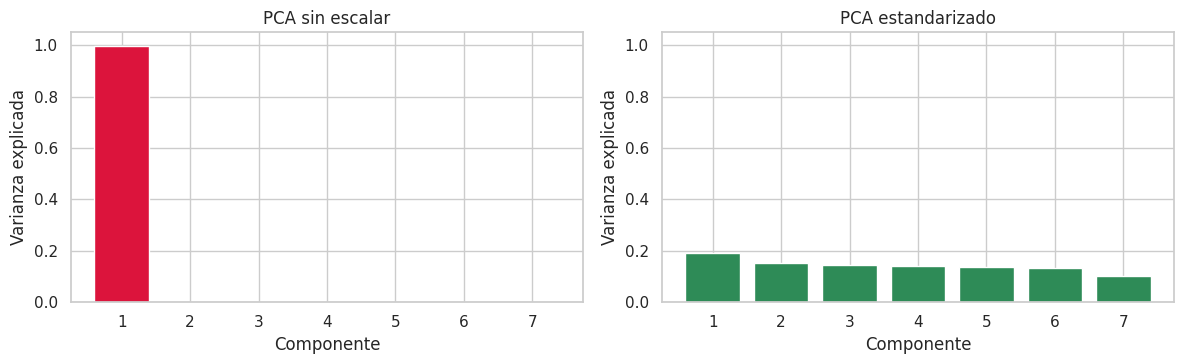

In [ ]:
# Gráfico: varianza explicada acumulada por cada componente
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(1, len(num_cols) + 1), pca_sin.explained_variance_ratio_, color='crimson'); ax[0].set_title('PCA sin escalar')
ax[1].bar(range(1, len(num_cols) + 1), pca_con.explained_variance_ratio_, color='seagreen'); ax[1].set_title('PCA estandarizado')
for a in ax: a.set_xlabel('Componente'); a.set_ylabel('Varianza explicada'); a.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

**Lectura:** sin estandarizar, PC1 explica el **99,8 %** de la varianza y su peso recae por completo en `saldo_cuenta` (1,000), que es justamente la variable de **ruido**: PCA no descubrió ninguna estructura, solo devolvió la variable de mayor escala. Estandarizado, PC1 explica el 19,1 % y reparte su peso entre `ingreso` (0,675), `gasto_mensual` (0,569) y `edad` (0,438), las variables que sí están relacionadas entre sí en este dataset (el ingreso crece con la edad, y el gasto con el ingreso).

## 8. Tabla resumen del impacto en modelos

In [ ]:
# Consolidamos todos los experimentos en una sola tabla
pd.DataFrame(resultados, columns=['Experimento', 'Variante', 'Métrica', 'Valor']).set_index(['Experimento', 'Variante'])

Métrica          Valor
Experimento                    Variante                                                                                        
Escalado en KNN                Sin escalar                                                         accuracy (CV)          0.648
                               Min-Max                                                             accuracy (CV)          0.622
                               Estandarizado                                                       accuracy (CV)          0.641
Unidad de saldo_cuenta en KNN  saldo en miles de $                       accuracy CV sin escalar / estandarizado  0.628 / 0.641
                               saldo en $ (original)                     accuracy CV sin escalar / estandarizado  0.647 / 0.641
                               saldo en centavos                         accuracy CV sin escalar / estandarizado  0.511 / 0.641
Escalado en Reg. Logística     Sin escalar                                           accuracy test / iteraciones    0.670 / 281
                               Estandarizado                                         accuracy test / iteraciones      0.698 / 6
Asimetría en Reg. Logística    Sin transformar                                               accuracy / AUC (CV)  0.683 / 0.764
                               Raíz cuadrada                                                 accuracy / AUC (CV)  0.693 / 0.769
                               Log1p                                                         accuracy / AUC (CV)  0.693 / 0.771
                               Box-Cox                                                       accuracy / AUC (CV)  0.694 / 0.771
                               Yeo-Johnson                                                   accuracy / AUC (CV)  0.694 / 0.771
Codificación en Reg. Logística 1. Solo numéricas                                     accuracy (CV) / nº columnas      0.693 / 7
                               2. + ciudad con Ordinal (incorrecto)                  accuracy (CV) / nº columnas      0.704 / 8
                               3. + ciudad One-Hot                                   accuracy (CV) / nº columnas     0.730 / 10
                               4. + ciudad One-Hot + educación Ordinal               accuracy (CV) / nº columnas     0.732 / 11
                               5. + todo + codigo_postal One-Hot (~300)              accuracy (CV) / nº columnas    0.721 / 310
PCA                            Sin escalar                                                varianza explicada PC1          99.8%
                               Estandarizado                                              varianza explicada PC1          19.1%

## Conclusiones

| Situación | Transformación recomendada | Evidencia en este notebook |
|---|---|---|
| Variables con escalas muy distintas, modelo basado en distancia o gradiente | **StandardScaler** (o Min-Max si se necesita [0, 1]) | `saldo_cuenta` aportaba 99,8 % de la distancia; KNN sin escalar cayó a 0,51 con otra unidad; la regresión logística pasó de 281 a 6 iteraciones |
| PCA | **StandardScaler siempre** | PC1 sin escalar = 99,8 % de la varianza, todo en la variable de ruido |
| Asimetría positiva fuerte | **log1p**, o **Box-Cox / Yeo-Johnson** si el log no basta | Skew de 2,04 → ≈ 0 en `ingreso`; mejora de +1 punto de accuracy; `log1p` sobrecorrigió `gasto_mensual` |
| Categórica nominal | **One-Hot** (`drop='first'` en modelos lineales) | +2,6 puntos de accuracy frente a Ordinal en `ciudad` |
| Categórica ordinal | **Ordinal con orden explícito** | Una sola columna, captura el orden |
| Alta cardinalidad | **Evitar One-Hot**; agrupar categorías raras o usar otra codificación | 300 columnas de ruido bajaron la accuracy |
| Siempre | **Split primero, `Pipeline` después** | Min-Max ajustado con train: en test los rangos se salen levemente de [0, 1] (comportamiento correcto) |

**Advertencias metodológicas**
- Los datos son sintéticos y fueron diseñados para que cada efecto sea visible; en datos reales la magnitud de las mejoras puede ser menor (aquí varias son de 1 a 3 puntos).
- Las métricas de modelos provienen de validación cruzada de 5 folds sobre 2000 filas, por lo que diferencias menores a ≈ 1 punto deben leerse con cautela.
- `saldo_cuenta` es una variable de ruido agregada a propósito para ilustrar el problema de escala.